In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
#

In [72]:
df=pd.read_csv('loan_data.csv')

In [73]:
df.head()

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


In [74]:
df.columns

Index(['person_age', 'person_gender', 'person_education', 'person_income',
       'person_emp_exp', 'person_home_ownership', 'loan_amnt', 'loan_intent',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length',
       'credit_score', 'previous_loan_defaults_on_file', 'loan_status'],
      dtype='object')

In [75]:
df.isnull().sum()

,0
person_age,0
person_gender,0
person_education,0
person_income,0
person_emp_exp,0
person_home_ownership,0
loan_amnt,0
loan_intent,0
loan_int_rate,0
loan_percent_income,0


In [76]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_gender                   45000 non-null  object 
 2   person_education                45000 non-null  object 
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  object 
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  object 
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 non-null  int64  
 12  previous_loan_defaults_on_file  

In [77]:
display(df.describe())

,person_age,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,loan_status
count,45000.000000,4.500000e+04,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000
mean,27.764178,8.031905e+04,5.410333,9583.157556,11.006606,0.139725,5.867489,632.608756,0.222222
std,6.045108,8.042250e+04,6.063532,6314.886691,2.978808,0.087212,3.879702,50.435865,0.415744
min,20.000000,8.000000e+03,0.000000,500.000000,5.420000,0.000000,2.000000,390.000000,0.000000
25%,24.000000,4.720400e+04,1.000000,5000.000000,8.590000,0.070000,3.000000,601.000000,0.000000
50%,26.000000,6.704800e+04,4.000000,8000.000000,11.010000,0.120000,4.000000,640.000000,0.000000
75%,30.000000,9.578925e+04,8.000000,12237.250000,12.990000,0.190000,8.000000,670.000000,0.000000
max,144.000000,7.200766e+06,125.000000,35000.000000,20.000000,0.660000,30.000000,850.000000,1.000000


In [78]:
display(df.describe(include='object'))

,person_gender,person_education,person_home_ownership,loan_intent,previous_loan_defaults_on_file
count,45000,45000,45000,45000,45000
unique,2,5,4,6,2
top,male,Bachelor,RENT,EDUCATION,Yes
freq,24841,13399,23443,9153,22858


In [79]:
df.duplicated().sum()

np.int64(0)

### Exploratory Data Analysis (EDA) by Target Column (`loan_status`)

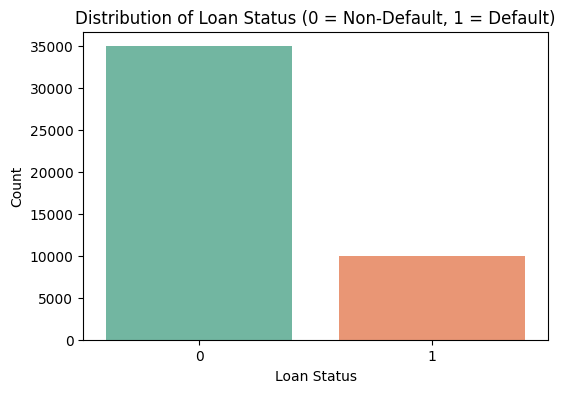

In [80]:
# 1. Target Variable Distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='loan_status', palette='Set2')
plt.title('Distribution of Loan Status (0 = Non-Default, 1 = Default)')
plt.xlabel('Loan Status')
plt.ylabel('Count')
plt.show()

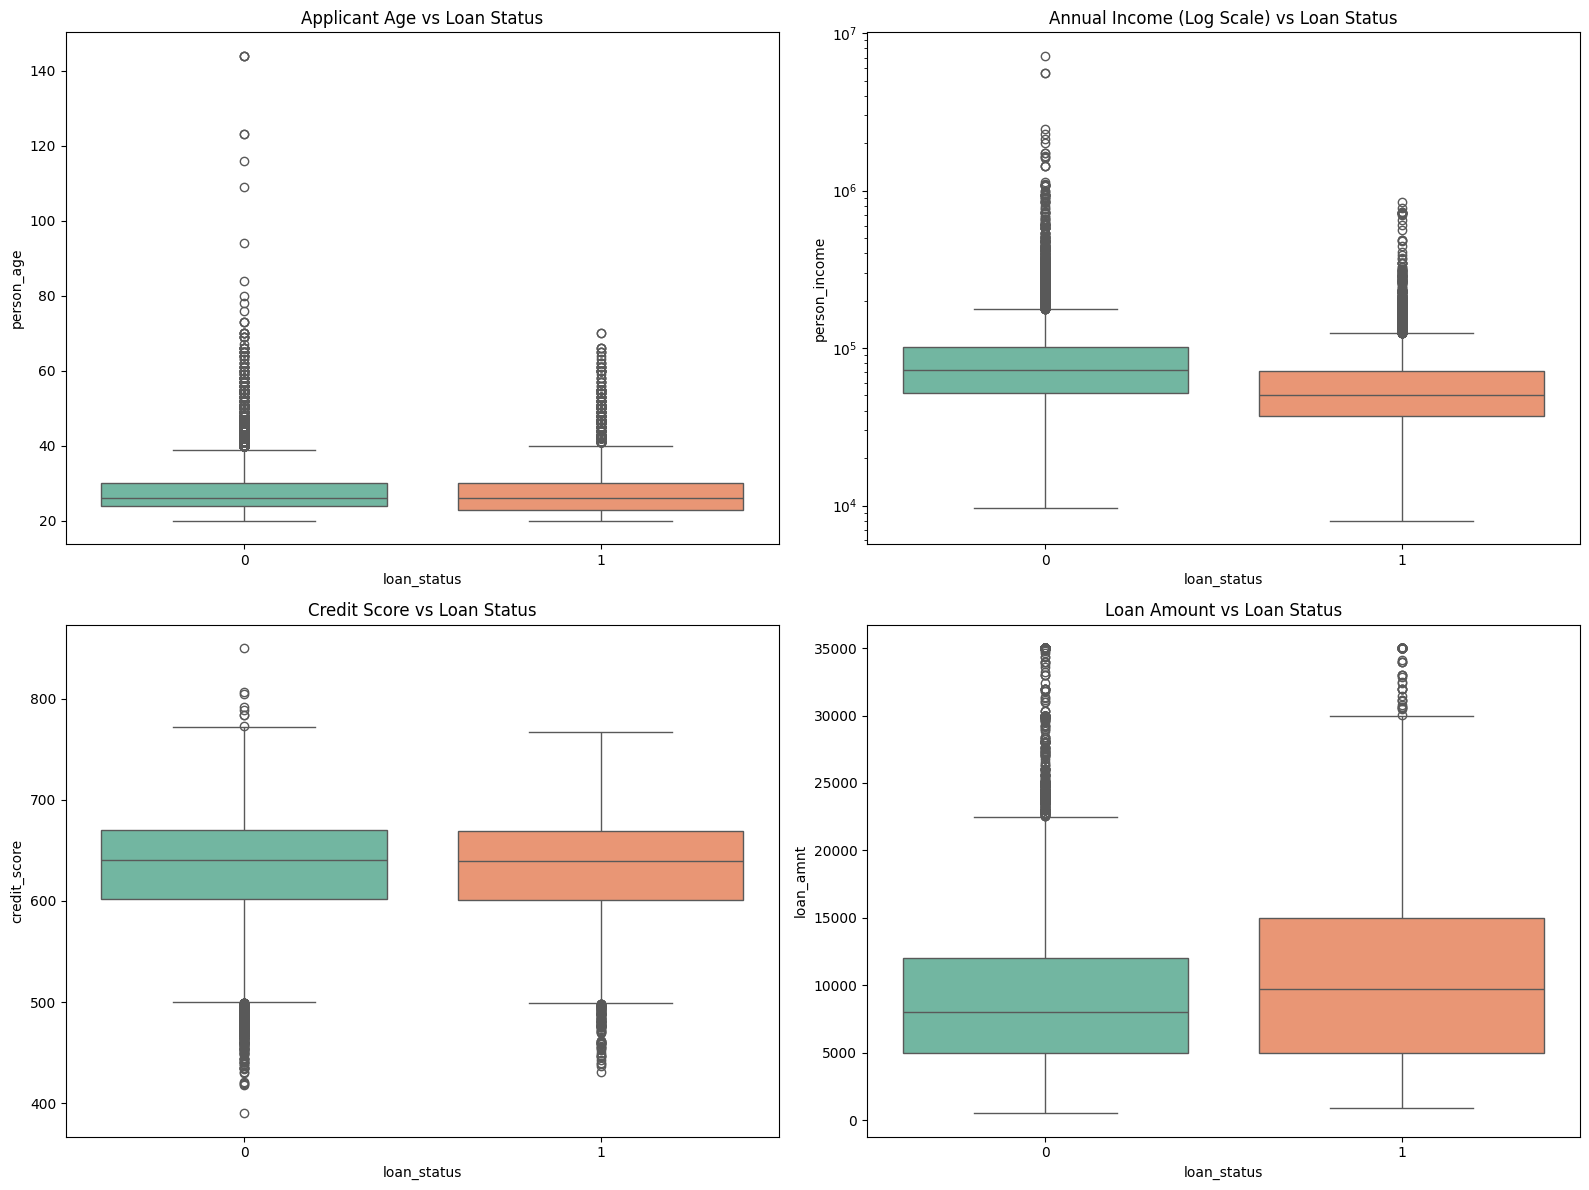

In [81]:
# 2. Analyzing Numerical Variables vs Loan Status
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Age vs Loan Status
sns.boxplot(data=df, x='loan_status', y='person_age', ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('Applicant Age vs Loan Status')

# Income vs Loan Status
sns.boxplot(data=df, x='loan_status', y='person_income', ax=axes[0, 1], palette='Set2')
axes[0, 1].set_yscale('log') # Log scale because income can have huge outliers
axes[0, 1].set_title('Annual Income (Log Scale) vs Loan Status')

# Credit Score vs Loan Status
sns.boxplot(data=df, x='loan_status', y='credit_score', ax=axes[1, 0], palette='Set2')
axes[1, 0].set_title('Credit Score vs Loan Status')

# Loan Amount vs Loan Status
sns.boxplot(data=df, x='loan_status', y='loan_amnt', ax=axes[1, 1], palette='Set2')
axes[1, 1].set_title('Loan Amount vs Loan Status')

plt.tight_layout()
plt.show()

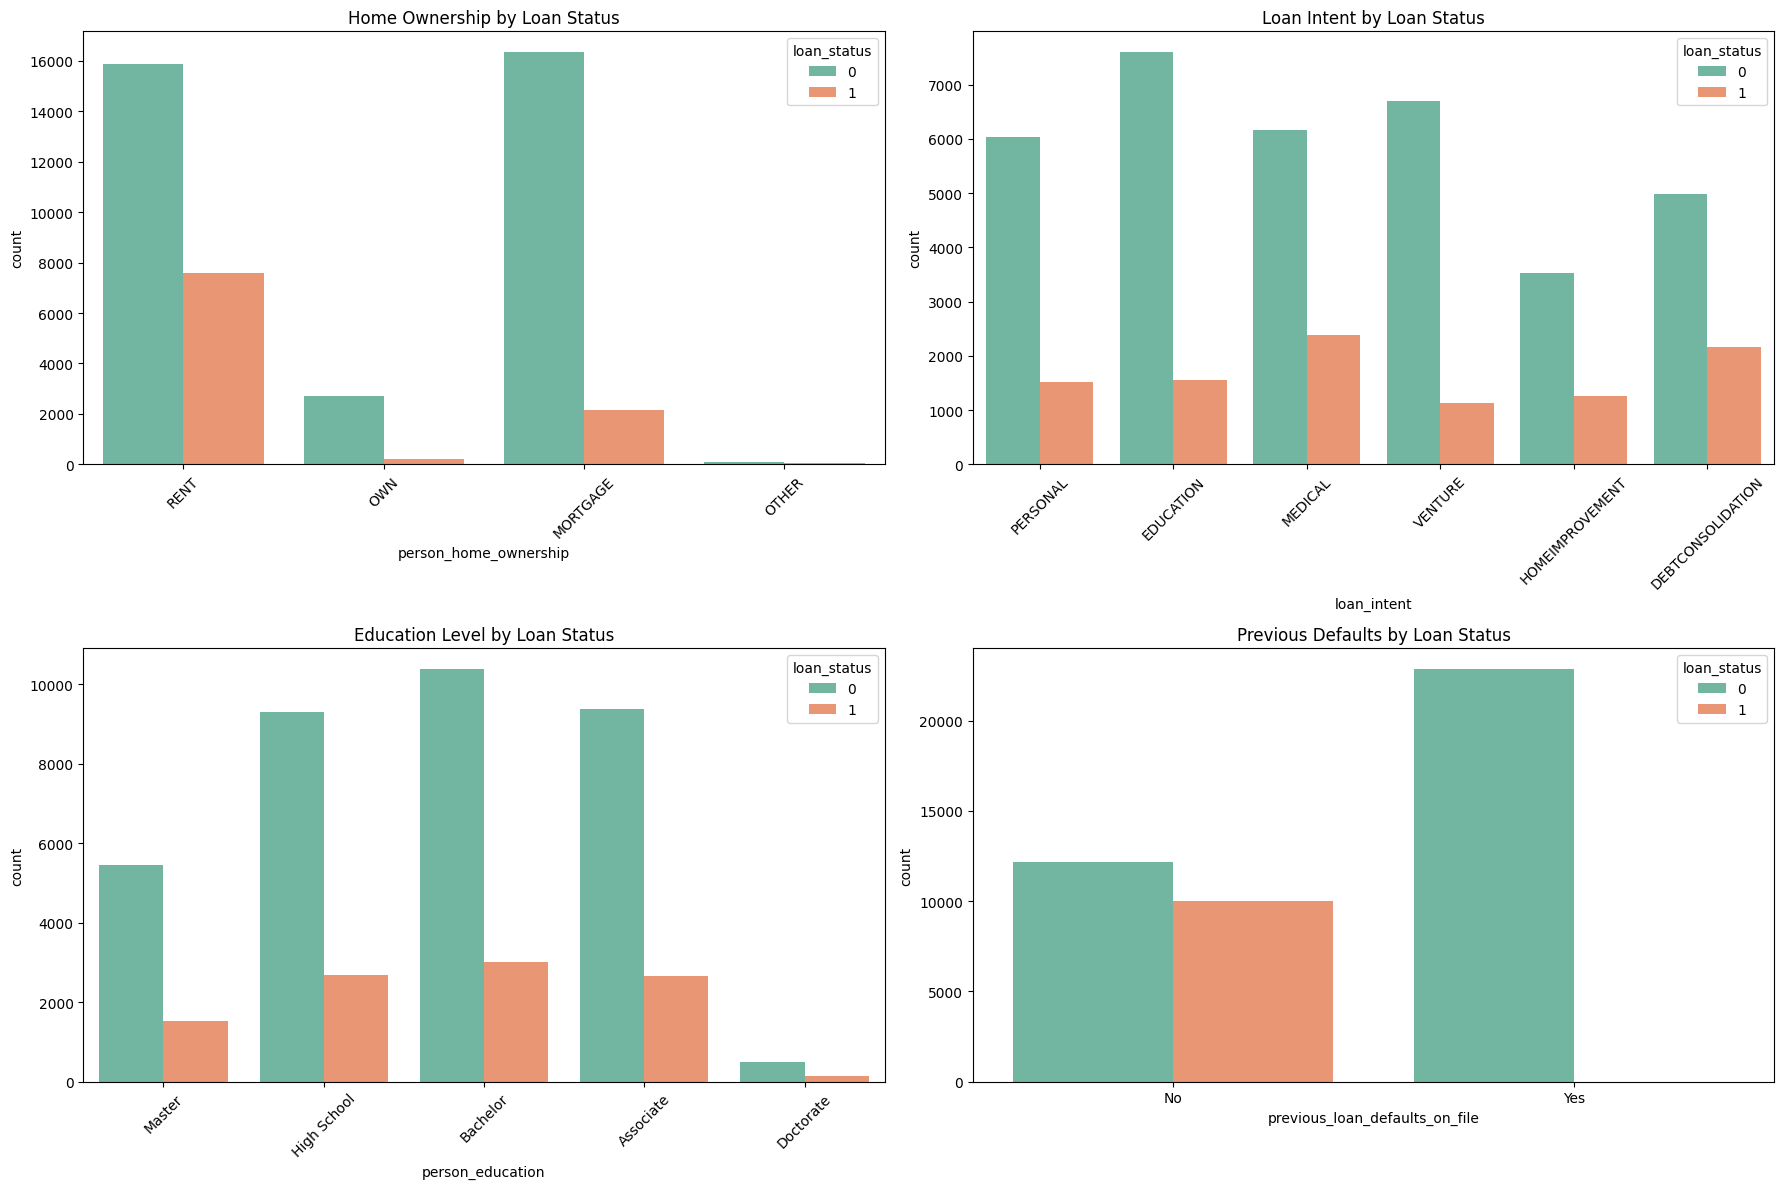

In [82]:
# 3. Analyzing Key Categorical Variables vs Loan Status
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Home Ownership vs Loan Status
sns.countplot(data=df, x='person_home_ownership', hue='loan_status', ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('Home Ownership by Loan Status')
axes[0, 0].tick_params(axis='x', rotation=45)

# Loan Intent vs Loan Status
sns.countplot(data=df, x='loan_intent', hue='loan_status', ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Loan Intent by Loan Status')
axes[0, 1].tick_params(axis='x', rotation=45)

# Education vs Loan Status
sns.countplot(data=df, x='person_education', hue='loan_status', ax=axes[1, 0], palette='Set2')
axes[1, 0].set_title('Education Level by Loan Status')
axes[1, 0].tick_params(axis='x', rotation=45)

# Previous Defaults vs Loan Status
sns.countplot(data=df, x='previous_loan_defaults_on_file', hue='loan_status', ax=axes[1, 1], palette='Set2')
axes[1, 1].set_title('Previous Defaults by Loan Status')

plt.tight_layout()
plt.show()

### Statistical Significance Testing against `loan_status`

In [83]:
from scipy.stats import chi2_contingency, ttest_ind

# 1. Chi-Square Test for Categorical Variables
categorical_cols = ['person_gender', 'person_education', 'person_home_ownership', 'loan_intent', 'previous_loan_defaults_on_file']
print("=== Chi-Square Test Results ===")
for col in categorical_cols:
    contingency_table = pd.crosstab(df[col], df['loan_status'])
    chi2, p, dof, expected = chi2_contingency(contingency_table)
    print(f"{col}: p-value = {p:.5e} -> {'Statistically Significant' if p < 0.05 else 'Not Significant'}")

# 2. T-Test for Numerical Variables
numerical_cols = ['person_age', 'person_income', 'person_emp_exp', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score']
print("\n=== T-Test Results ===")
for col in numerical_cols:
    group0 = df[df['loan_status'] == 0][col]
    group1 = df[df['loan_status'] == 1][col]
    t_stat, p = ttest_ind(group0, group1, equal_var=False)
    print(f"{col}: p-value = {p:.5e} -> {'Statistically Significant' if p < 0.05 else 'Not Significant'}")

=== Chi-Square Test Results ===
person_gender: p-value = 9.14254e-01 -> Not Significant
person_education: p-value = 7.32827e-01 -> Not Significant
person_home_ownership: p-value = 0.00000e+00 -> Statistically Significant
loan_intent: p-value = 2.17308e-194 -> Statistically Significant
previous_loan_defaults_on_file: p-value = 0.00000e+00 -> Statistically Significant

=== T-Test Results ===
person_age: p-value = 3.98614e-06 -> Statistically Significant
person_income: p-value = 0.00000e+00 -> Statistically Significant
person_emp_exp: p-value = 9.79684e-06 -> Statistically Significant
loan_amnt: p-value = 4.10788e-96 -> Statistically Significant
loan_int_rate: p-value = 0.00000e+00 -> Statistically Significant
loan_percent_income: p-value = 0.00000e+00 -> Statistically Significant
cb_person_cred_hist_length: p-value = 1.71621e-03 -> Statistically Significant
credit_score: p-value = 1.04080e-01 -> Not Significant


### Statistical Significance Testing against `loan_status`

In [84]:
from scipy.stats import chi2_contingency, ttest_ind

# 1. Chi-Square Test for Categorical Variables
categorical_cols = ['person_gender', 'person_education', 'person_home_ownership', 'loan_intent', 'previous_loan_defaults_on_file']
print("=== Chi-Square Test Results ===")
for col in categorical_cols:
    contingency_table = pd.crosstab(df[col], df['loan_status'])
    chi2, p, dof, expected = chi2_contingency(contingency_table)
    print(f"{col}: p-value = {p:.5e} -> {'Statistically Significant' if p < 0.05 else 'Not Significant'}")

# 2. T-Test for Numerical Variables
numerical_cols = ['person_age', 'person_income', 'person_emp_exp', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score']
print("\n=== T-Test Results ===")
for col in numerical_cols:
    group0 = df[df['loan_status'] == 0][col]
    group1 = df[df['loan_status'] == 1][col]
    t_stat, p = ttest_ind(group0, group1, equal_var=False)
    print(f"{col}: p-value = {p:.5e} -> {'Statistically Significant' if p < 0.05 else 'Not Significant'}")

=== Chi-Square Test Results ===
person_gender: p-value = 9.14254e-01 -> Not Significant
person_education: p-value = 7.32827e-01 -> Not Significant
person_home_ownership: p-value = 0.00000e+00 -> Statistically Significant
loan_intent: p-value = 2.17308e-194 -> Statistically Significant
previous_loan_defaults_on_file: p-value = 0.00000e+00 -> Statistically Significant

=== T-Test Results ===
person_age: p-value = 3.98614e-06 -> Statistically Significant
person_income: p-value = 0.00000e+00 -> Statistically Significant
person_emp_exp: p-value = 9.79684e-06 -> Statistically Significant
loan_amnt: p-value = 4.10788e-96 -> Statistically Significant
loan_int_rate: p-value = 0.00000e+00 -> Statistically Significant
loan_percent_income: p-value = 0.00000e+00 -> Statistically Significant
cb_person_cred_hist_length: p-value = 1.71621e-03 -> Statistically Significant
credit_score: p-value = 1.04080e-01 -> Not Significant


In [85]:
categorical_features_onehot = ['person_gender', 'person_education', 'person_home_ownership', 'loan_intent']
categorical_feature_label = 'previous_loan_defaults_on_file'

print("Categorical features for One-Hot Encoding:", categorical_features_onehot)
print("Categorical feature for Label Encoding:", categorical_feature_label)

Categorical features for One-Hot Encoding: ['person_gender', 'person_education', 'person_home_ownership', 'loan_intent']
Categorical feature for Label Encoding: previous_loan_defaults_on_file


In [86]:
df = pd.get_dummies(df, columns=categorical_features_onehot, drop_first=True)
df['previous_loan_defaults_on_file'] = df['previous_loan_defaults_on_file'].map({'No': 0, 'Yes': 1})

print('DataFrame after encoding:')
df.head()
df.info()

DataFrame after encoding:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 23 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_income                   45000 non-null  float64
 2   person_emp_exp                  45000 non-null  int64  
 3   loan_amnt                       45000 non-null  float64
 4   loan_int_rate                   45000 non-null  float64
 5   loan_percent_income             45000 non-null  float64
 6   cb_person_cred_hist_length      45000 non-null  float64
 7   credit_score                    45000 non-null  int64  
 8   previous_loan_defaults_on_file  45000 non-null  int64  
 9   loan_status                     45000 non-null  int64  
 10  person_gender_male              45000 non-null  bool   
 11  person_education_Bachelor       45000 non-null  bool   
 12  person

In [87]:
df.head()

,person_age,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status,...,person_education_High School,person_education_Master,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE
0,22.0,71948.0,0,35000.0,16.02,0.49,3.0,561,0,1,...,False,True,False,False,True,False,False,False,True,False
1,21.0,12282.0,0,1000.0,11.14,0.08,2.0,504,1,0,...,True,False,False,True,False,True,False,False,False,False
2,25.0,12438.0,3,5500.0,12.87,0.44,3.0,635,0,1,...,True,False,False,False,False,False,False,True,False,False
3,23.0,79753.0,0,35000.0,15.23,0.44,2.0,675,0,1,...,False,False,False,False,True,False,False,True,False,False
4,24.0,66135.0,1,35000.0,14.27,0.53,4.0,586,0,1,...,False,True,False,False,True,False,False,True,False,False


In [88]:
# 1. Safely convert Boolean columns to 1 and 0
bool_cols = df.select_dtypes(include=['bool']).columns
df[bool_cols] = df[bool_cols].replace({True: 1, False: 0})

# 2. Check the data types to verify the boolean columns are now integers
display(df.info())
display(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 23 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_income                   45000 non-null  float64
 2   person_emp_exp                  45000 non-null  int64  
 3   loan_amnt                       45000 non-null  float64
 4   loan_int_rate                   45000 non-null  float64
 5   loan_percent_income             45000 non-null  float64
 6   cb_person_cred_hist_length      45000 non-null  float64
 7   credit_score                    45000 non-null  int64  
 8   previous_loan_defaults_on_file  45000 non-null  int64  
 9   loan_status                     45000 non-null  int64  
 10  person_gender_male              45000 non-null  int64  
 11  person_education_Bachelor       45000 non-null  int64  
 12  person_education_Doctorate      

None

,person_age,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status,...,person_education_High School,person_education_Master,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE
0,22.0,71948.0,0,35000.0,16.02,0.49,3.0,561,0,1,...,0,1,0,0,1,0,0,0,1,0
1,21.0,12282.0,0,1000.0,11.14,0.08,2.0,504,1,0,...,1,0,0,1,0,1,0,0,0,0
2,25.0,12438.0,3,5500.0,12.87,0.44,3.0,635,0,1,...,1,0,0,0,0,0,0,1,0,0
3,23.0,79753.0,0,35000.0,15.23,0.44,2.0,675,0,1,...,0,0,0,0,1,0,0,1,0,0
4,24.0,66135.0,1,35000.0,14.27,0.53,4.0,586,0,1,...,0,1,0,0,1,0,0,1,0,0


### Next Step: Handling the remaining missing values (NaN)
Since we only have 1 missing row with NaN values in columns like `loan_int_rate` and `loan_status`, we can safely drop that single incomplete row to ensure our dataset is fully clean for modeling.

In [89]:
# Drop rows with missing values
df = df.dropna()

# Confirm that no missing values remain
print("Remaining missing values:")
print(df.isnull().sum().sum())

Remaining missing values:
0


In [90]:
X = df.drop('loan_status',axis = 1)
y = df['loan_status']

In [91]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [92]:
from sklearn.naive_bayes import GaussianNB
nb_model = GaussianNB()

In [93]:
nb_model.fit(X_train,y_train)

GaussianNB()

In [94]:
y_pred = nb_model.predict(X_test)


In [95]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

0.8025555555555556
              precision    recall  f1-score   support

           0       0.82      0.96      0.88      6990
           1       0.64      0.26      0.37      2010

    accuracy                           0.80      9000
   macro avg       0.73      0.61      0.63      9000
weighted avg       0.78      0.80      0.77      9000

[[6692  298]
 [1479  531]]


### Removing Outliers and Retraining the Naive Bayes Model
Let's apply the IQR method to remove extreme outliers in `person_age` and `person_income` to see if the `GaussianNB` model's performance improves.

In [96]:
numerical_cols = [
    'person_age',
    'person_income',
    'person_emp_exp',
    'loan_amnt',
    'loan_int_rate',
    'loan_percent_income',
    'cb_person_cred_hist_length',
    'credit_score'
]

print('--- Outlier Detection using IQR Method ---')
for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)][col]

    print(f'\nColumn: {col}')
    print(f'  Number of outliers: {len(outliers)}')
    if not outliers.empty:
        print(f'  Outlier values (first 5 if many):\n{outliers.head()}')


--- Outlier Detection using IQR Method ---

Column: person_age
  Number of outliers: 2188
  Outlier values (first 5 if many):
81       144.0
183      144.0
575      123.0
747      123.0
29120     40.0
Name: person_age, dtype: float64

Column: person_income
  Number of outliers: 2218
  Outlier values (first 5 if many):
15    600891.0
20    195718.0
33    368115.0
34    361076.0
42    361293.0
Name: person_income, dtype: float64

Column: person_emp_exp
  Number of outliers: 1724
  Outlier values (first 5 if many):
81       125
183      121
575      101
747      100
29120     19
Name: person_emp_exp, dtype: int64

Column: loan_amnt
  Number of outliers: 2348
  Outlier values (first 5 if many):
0    35000.0
3    35000.0
4    35000.0
6    35000.0
7    35000.0
Name: loan_amnt, dtype: float64

Column: loan_int_rate
  Number of outliers: 124
  Outlier values (first 5 if many):
17     20.00
112    19.91
349    19.74
420    19.69
440    19.69
Name: loan_int_rate, dtype: float64

Column: loan_per

In [97]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 23 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_income                   45000 non-null  float64
 2   person_emp_exp                  45000 non-null  int64  
 3   loan_amnt                       45000 non-null  float64
 4   loan_int_rate                   45000 non-null  float64
 5   loan_percent_income             45000 non-null  float64
 6   cb_person_cred_hist_length      45000 non-null  float64
 7   credit_score                    45000 non-null  int64  
 8   previous_loan_defaults_on_file  45000 non-null  int64  
 9   loan_status                     45000 non-null  int64  
 10  person_gender_male              45000 non-null  int64  
 11  person_education_Bachelor       45000 non-null  int64  
 12  person_education_Doctorate      

In [98]:
print(f"DataFrame shape before outlier removal: {df.shape}")

numerical_cols_for_outlier_removal = [
    'person_age',
    'person_income',
    'person_emp_exp',
    'loan_amnt',
    'loan_int_rate',
    'cb_person_cred_hist_length',
    'credit_score'
]

for col in numerical_cols_for_outlier_removal:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

print(f"DataFrame shape after outlier removal: {df.shape}")

DataFrame shape before outlier removal: (45000, 23)
DataFrame shape after outlier removal: (37267, 23)


In [99]:
numerical_cols_for_outlier_removal = [
    'person_age',
    'person_income',
    'person_emp_exp',
    'loan_amnt',
    'loan_int_rate',
    'cb_person_cred_hist_length',
    'credit_score'
]

print('--- Verification of Outlier Removal using IQR Method ---')
for col in numerical_cols_for_outlier_removal:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)][col]

    print(f'\nColumn: {col}')
    print(f'  Number of outliers remaining: {len(outliers)}')

print(f"\nFinal DataFrame shape after outlier removal verification: {df.shape}")

--- Verification of Outlier Removal using IQR Method ---

Column: person_age
  Number of outliers remaining: 74

Column: person_income
  Number of outliers remaining: 500

Column: person_emp_exp
  Number of outliers remaining: 834

Column: loan_amnt
  Number of outliers remaining: 0

Column: loan_int_rate
  Number of outliers remaining: 3

Column: cb_person_cred_hist_length
  Number of outliers remaining: 0

Column: credit_score
  Number of outliers remaining: 60

Final DataFrame shape after outlier removal verification: (37267, 23)


In [100]:
X = df.drop('loan_status',axis = 1)
y = df['loan_status']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [101]:
new_model = GaussianNB()
new_model.fit(X_train, y_train)
y_pred = new_model.predict(X_test)

In [102]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

0.8414274215186477
              precision    recall  f1-score   support

           0       0.85      0.96      0.90      5790
           1       0.77      0.42      0.54      1664

    accuracy                           0.84      7454
   macro avg       0.81      0.69      0.72      7454
weighted avg       0.83      0.84      0.82      7454

[[5580  210]
 [ 972  692]]


In [103]:
import pickle
with open('model_naive.pkl', 'wb') as file:
    pickle.dump(model, file)

NameError: name 'model' is not defined

In [104]:
import pickle
import os

# Save the corrected variable 'new_model'
with open('model_naive.pkl', 'wb') as file:
    pickle.dump(new_model, file)

# Verify that the file has been successfully written
if os.path.exists('model_naive.pkl'):
    print("Success: 'model_naive.pkl' has been created and saved successfully!")
else:
    print("Error: File was not created.")

Success: 'model_naive.pkl' has been created and saved successfully!
